In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

EXPERIMENTS = PROJECT_ROOT / "experiments"
sys.path.insert(0, str(EXPERIMENTS))

from landau_damping.convergence import run_landau_damping
print("Convergence experiment imported successfully.")

Convergence experiment imported successfully.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.stats import linregress

In [4]:
result = run_landau_damping(
    Nx=32,
    Nv=32,
    t_final=10.0,
)

print("Nx =", result["Nx"])
print("Nv =", result["Nv"])
print("gamma =", result["gamma"])
print("R² =", result["r_squared"])

t=0.0000, max|f|=3.954548e-01, max|E|=2.000000e-02
t=1.0000, max|f|=3.956606e-01, max|E|=9.234488e-03
t=2.0000, max|f|=3.956488e-01, max|E|=7.166181e-03
t=3.0000, max|f|=3.953826e-01, max|E|=7.423875e-03
t=4.0000, max|f|=3.953087e-01, max|E|=3.280831e-03
t=5.0000, max|f|=3.955377e-01, max|E|=6.058671e-03
t=6.0000, max|f|=3.956846e-01, max|E|=9.209504e-04
t=7.0000, max|f|=3.954901e-01, max|E|=4.564018e-03
t=8.0000, max|f|=3.953425e-01, max|E|=4.101466e-04
t=9.0000, max|f|=3.954455e-01, max|E|=3.180541e-03
Nx = 32
Nv = 32
gamma = 0.16782925926165468
R² = 0.9999067142533148


In [5]:
resolutions = [
    (32, 32),
    (64, 64),
    (128, 128),
    (256, 256),
]

results = []

for Nx, Nv in resolutions:

    print(
        f"\nRunning {Nx} × {Nv} "
        f"({Nx * Nv:,} phase-space points)..."
    )

    result = run_landau_damping(
    Nx=32,
    Nv=32,
    dt=0.001,
    t_final=20.0,
    fit_damping=True,
)
    results.append(result)

    print(
        f"gamma = {result['gamma']:.6f}, "
        f"R² = {result['r_squared']:.6f}"
    )


Running 32 × 32 (1,024 phase-space points)...
t=0.0000, max|f|=3.954548e-01, max|E|=2.000000e-02
t=0.1000, max|f|=3.954540e-01, max|E|=1.987519e-02
t=0.2000, max|f|=3.954514e-01, max|E|=1.950296e-02
t=0.3000, max|f|=3.954755e-01, max|E|=1.888993e-02
t=0.4000, max|f|=3.955025e-01, max|E|=1.804695e-02
t=0.5000, max|f|=3.955266e-01, max|E|=1.698895e-02
t=0.6000, max|f|=3.955476e-01, max|E|=1.573456e-02
t=0.7000, max|f|=3.955652e-01, max|E|=1.430580e-02
t=0.8000, max|f|=3.955987e-01, max|E|=1.272762e-02
t=0.9000, max|f|=3.956325e-01, max|E|=1.102742e-02
t=1.0000, max|f|=3.956606e-01, max|E|=9.234488e-03
t=1.1000, max|f|=3.956829e-01, max|E|=7.379432e-03
t=1.2000, max|f|=3.956995e-01, max|E|=5.493596e-03
t=1.3000, max|f|=3.957103e-01, max|E|=3.608443e-03
t=1.4000, max|f|=3.957156e-01, max|E|=1.754959e-03
t=1.5000, max|f|=3.957157e-01, max|E|=3.785542e-05
t=1.6000, max|f|=3.957107e-01, max|E|=1.738932e-03
t=1.7000, max|f|=3.957011e-01, max|E|=3.324875e-03
t=1.8000, max|f|=3.956873e-01, max|

KeyboardInterrupt: 

In [10]:
result = run_landau_damping(
    Nx=32,
    Nv=32,
    dt=0.001,
    t_final=20.0,
    fit_damping=True,
)
print("Gamma =", result["gamma"])
print("R² =", result["r_squared"])

print(
    "Maximum |f| =",
    np.max(np.abs(result["f_final"]))
)

print(
    "Finite solution =",
    np.all(np.isfinite(result["f_final"]))
)

print("Simulation completed.")
print("Maximum |f| =", np.max(np.abs(result["f_final"])))
print("Finite solution =", np.all(np.isfinite(result["f_final"])))

t=0.0000, max|f|=3.954548e-01, max|E|=2.000000e-02
t=0.1000, max|f|=3.954540e-01, max|E|=1.987519e-02
t=0.2000, max|f|=3.954514e-01, max|E|=1.950296e-02
t=0.3000, max|f|=3.954755e-01, max|E|=1.888993e-02
t=0.4000, max|f|=3.955025e-01, max|E|=1.804695e-02
t=0.5000, max|f|=3.955266e-01, max|E|=1.698895e-02
t=0.6000, max|f|=3.955476e-01, max|E|=1.573456e-02
t=0.7000, max|f|=3.955652e-01, max|E|=1.430580e-02
t=0.8000, max|f|=3.955987e-01, max|E|=1.272762e-02
t=0.9000, max|f|=3.956325e-01, max|E|=1.102742e-02
t=1.0000, max|f|=3.956606e-01, max|E|=9.234488e-03
t=1.1000, max|f|=3.956829e-01, max|E|=7.379432e-03
t=1.2000, max|f|=3.956995e-01, max|E|=5.493596e-03
t=1.3000, max|f|=3.957103e-01, max|E|=3.608443e-03
t=1.4000, max|f|=3.957156e-01, max|E|=1.754959e-03
t=1.5000, max|f|=3.957157e-01, max|E|=3.785542e-05
t=1.6000, max|f|=3.957107e-01, max|E|=1.738932e-03
t=1.7000, max|f|=3.957011e-01, max|E|=3.324875e-03
t=1.8000, max|f|=3.956873e-01, max|E|=4.771201e-03
t=1.9000, max|f|=3.956697e-01, 

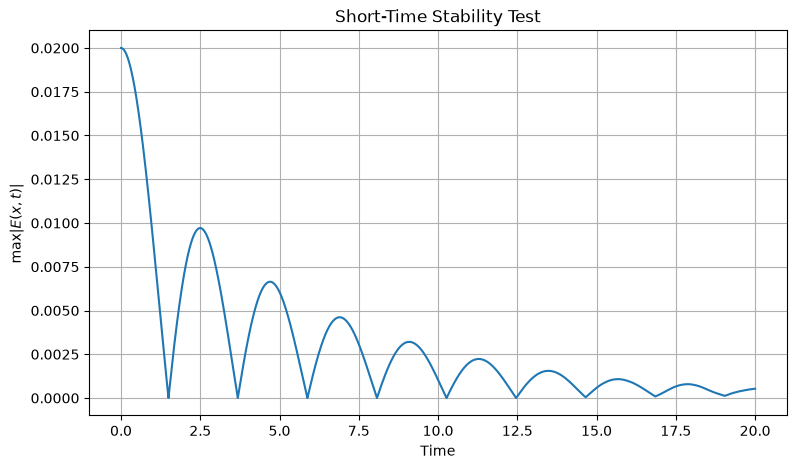

In [11]:
plt.figure(figsize=(9, 5))

plt.plot(
    result["times"],
    result["field_amplitudes"],
)

plt.xlabel("Time")
plt.ylabel(r"$\max |E(x,t)|$")
plt.title("Short-Time Stability Test")

plt.grid(True)
plt.show()

In [12]:
import pandas as pd

convergence_table = pd.DataFrame([
    {
        "Nx": r["Nx"],
        "Nv": r["Nv"],
        "DOF": r["Nx"] * r["Nv"],
        "Gamma": r["gamma"],
        "R_squared": r["r_squared"],
    }
    for r in results
])

convergence_table

,Nx,Nv,DOF,Gamma,R_squared
0,32,32,1024,0.164271,0.99963
1,32,32,1024,0.164271,0.99963
2,32,32,1024,0.164271,0.99963


In [14]:
import pandas as pd
import numpy as np

resolutions = [
    (32, 32),
    (64, 64),
    (128, 128),
]

results = []

for Nx, Nv in resolutions:

    print(f"Running Nx={Nx}, Nv={Nv}...")

    result = run_landau_damping(
        Nx=Nx,
        Nv=Nv,
        dt=0.001,
        t_final=20.0,
        fit_damping=True,
    )

    results.append({
        "Nx": Nx,
        "Nv": Nv,
        "DOF": Nx * Nv,
        "Gamma": result["gamma"],
        "R²": result["r_squared"],
    })

    print(
        f"Gamma = {result['gamma']:.6f}, "
        f"R² = {result['r_squared']:.6f}"
    )

convergence_table = pd.DataFrame(results)

convergence_table

Running Nx=32, Nv=32...
t=0.0000, max|f|=3.954548e-01, max|E|=2.000000e-02
t=0.1000, max|f|=3.954540e-01, max|E|=1.987519e-02
t=0.2000, max|f|=3.954514e-01, max|E|=1.950296e-02
t=0.3000, max|f|=3.954755e-01, max|E|=1.888993e-02
t=0.4000, max|f|=3.955025e-01, max|E|=1.804695e-02
t=0.5000, max|f|=3.955266e-01, max|E|=1.698895e-02
t=0.6000, max|f|=3.955476e-01, max|E|=1.573456e-02
t=0.7000, max|f|=3.955652e-01, max|E|=1.430580e-02
t=0.8000, max|f|=3.955987e-01, max|E|=1.272762e-02
t=0.9000, max|f|=3.956325e-01, max|E|=1.102742e-02
t=1.0000, max|f|=3.956606e-01, max|E|=9.234488e-03
t=1.1000, max|f|=3.956829e-01, max|E|=7.379432e-03
t=1.2000, max|f|=3.956995e-01, max|E|=5.493596e-03
t=1.3000, max|f|=3.957103e-01, max|E|=3.608443e-03
t=1.4000, max|f|=3.957156e-01, max|E|=1.754959e-03
t=1.5000, max|f|=3.957157e-01, max|E|=3.785542e-05
t=1.6000, max|f|=3.957107e-01, max|E|=1.738932e-03
t=1.7000, max|f|=3.957011e-01, max|E|=3.324875e-03
t=1.8000, max|f|=3.956873e-01, max|E|=4.771201e-03
t=1.900

,Nx,Nv,DOF,Gamma,R²
0,32,32,1024,0.164271,0.999630
1,64,64,4096,0.157191,0.999975
2,128,128,16384,0.154945,0.999974


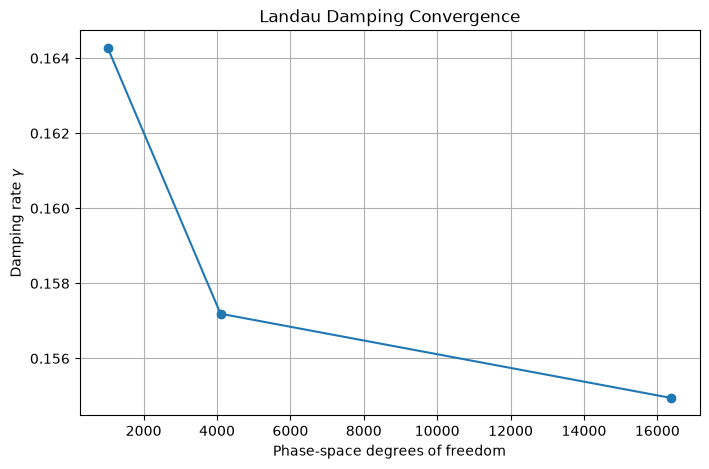

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    convergence_table["DOF"],
    convergence_table["Gamma"],
    "o-",
)

plt.xlabel("Phase-space degrees of freedom")
plt.ylabel(r"Damping rate $\gamma$")
plt.title("Landau Damping Convergence")

plt.grid(True)
plt.show()

In [17]:
import pandas as pd

time_steps = [
    0.002,
    0.001,
    0.0005,
]

time_results = []

for dt in time_steps:

    print(f"Running dt={dt}...")

    result = run_landau_damping(
        Nx=128,
        Nv=128,
        dt=dt,
        t_final=20.0,
        fit_damping=True,
    )

    time_results.append({
        "dt": dt,
        "Gamma": result["gamma"],
        "R²": result["r_squared"],
    })

    print(
        f"Gamma = {result['gamma']:.6f}, "
        f"R² = {result['r_squared']:.6f}"
    )

time_table = pd.DataFrame(time_results)

time_table

Running dt=0.002...
t=0.0000, max|f|=4.024823e-01, max|E|=2.000000e-02
t=0.2000, max|f|=4.024821e-01, max|E|=1.950291e-02
t=0.4000, max|f|=4.024856e-01, max|E|=1.804622e-02
t=0.6000, max|f|=4.024886e-01, max|E|=1.573096e-02
t=0.8000, max|f|=4.024927e-01, max|E|=1.271677e-02
t=1.0000, max|f|=4.024968e-01, max|E|=9.209519e-03
t=1.2000, max|f|=4.024993e-01, max|E|=5.445456e-03
t=1.4000, max|f|=4.025003e-01, max|E|=1.673235e-03
t=1.6000, max|f|=4.024998e-01, max|E|=1.864750e-03
t=1.8000, max|f|=4.024981e-01, max|E|=4.950139e-03
t=2.0000, max|f|=4.024954e-01, max|E|=7.404118e-03
t=2.2000, max|f|=4.024919e-01, max|E|=9.099457e-03
t=2.4000, max|f|=4.024880e-01, max|E|=9.968234e-03
t=2.6000, max|f|=4.024840e-01, max|E|=1.000473e-02
t=2.8000, max|f|=4.024801e-01, max|E|=9.263436e-03
t=3.0000, max|f|=4.024767e-01, max|E|=7.852434e-03
t=3.2000, max|f|=4.024740e-01, max|E|=5.922939e-03
t=3.4000, max|f|=4.024721e-01, max|E|=3.655889e-03
t=3.6000, max|f|=4.024710e-01, max|E|=1.246839e-03
t=3.8000, m

,dt,Gamma,R²
0,0.0020,0.154947,0.999974
1,0.0010,0.154945,0.999974
2,0.0005,0.154948,0.999974
